<a href="https://colab.research.google.com/github/juchi6/data-science-lab/blob/main/Introduction_to_data_science_with_python(Linear_Regression)_lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Linear Regression Using Python
## Advertising Sales prediction - Supervised Learning
To build a simple linear regression model with StatsModels.

In [2]:
#1 Import the required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import kagglehub
import os
path = kagglehub.dataset_download("mehmetisik/advertisingcsv")

print(os.listdir(path))

Using Colab cache for faster access to the 'advertisingcsv' dataset.
['advertising.csv']


In [3]:
# Load the dataset from a CSV in your project folder
data = pd.read_csv(os.path.join(path, "advertising.csv"))

data.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [4]:
# Check data types and missing values
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   radio      200 non-null    float64
 2   newspaper  200 non-null    float64
 3   sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB
None


In [5]:
# Summary Statistics
print(data.describe())

               TV       radio   newspaper       sales
count  200.000000  200.000000  200.000000  200.000000
mean   147.042500   23.264000   30.554000   14.022500
std     85.854236   14.846809   21.778621    5.217457
min      0.700000    0.000000    0.300000    1.600000
25%     74.375000    9.975000   12.750000   10.375000
50%    149.750000   22.900000   25.750000   12.900000
75%    218.825000   36.525000   45.100000   17.400000
max    296.400000   49.600000  114.000000   27.000000


In [6]:
# Include all columns
print(data.describe(include='all'))

               TV       radio   newspaper       sales
count  200.000000  200.000000  200.000000  200.000000
mean   147.042500   23.264000   30.554000   14.022500
std     85.854236   14.846809   21.778621    5.217457
min      0.700000    0.000000    0.300000    1.600000
25%     74.375000    9.975000   12.750000   10.375000
50%    149.750000   22.900000   25.750000   12.900000
75%    218.825000   36.525000   45.100000   17.400000
max    296.400000   49.600000  114.000000   27.000000


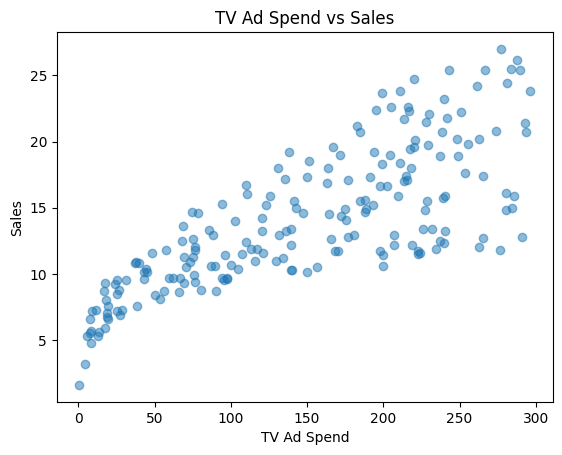

In [7]:
# Visualize relationships between TV ad channel and Sales:
plt.scatter(data["TV"], data["sales"], alpha=0.5)
# the alpha paramters controls the transparency of the plotted markers.
# alpha = 0: Completely transparent (invisible). alpha = 1: opaque (solid).
plt.xlabel("TV Ad Spend")
plt.ylabel("Sales")
plt.title("TV Ad Spend vs Sales")
plt.show()

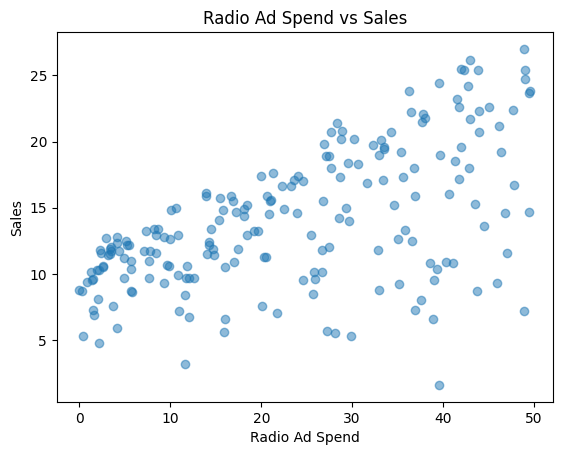

In [8]:
# Visualize relationships between Radio ad channel and Sales:
plt.scatter(data["radio"], data["sales"], alpha=0.5)
# the alpha paramters controls the transparency of the plotted markers.
# alpha = 0: Completely transparent (invisible). alpha = 1: opaque (solid).
plt.xlabel("Radio Ad Spend")
plt.ylabel("Sales")
plt.title("Radio Ad Spend vs Sales")
plt.show()

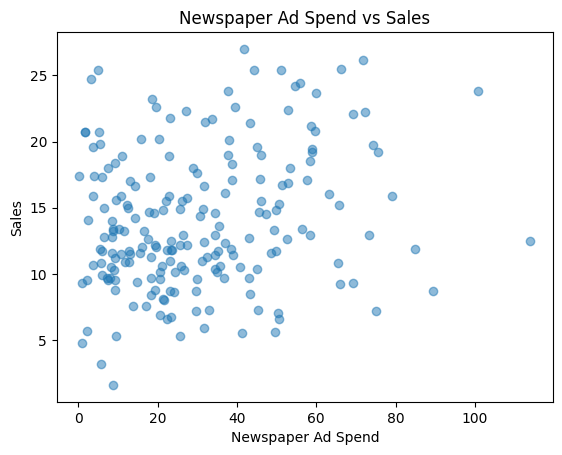

In [9]:
# Visualize relationships between Newspaper ad channel and Sales:
plt.scatter(data["newspaper"], data["sales"], alpha=0.5)
# the alpha paramters controls the transparency of the plotted markers.
# alpha = 0: Completely transparent (invisible). alpha = 1: opaque (solid).
plt.xlabel("Newspaper Ad Spend")
plt.ylabel("Sales")
plt.title("Newspaper Ad Spend vs Sales")
plt.show()

In [10]:
# Create Linear Regression Model
# Our Independent variables (Predictors)
X = data[["TV", "radio", "newspaper"]]
print(X)

        TV  radio  newspaper
0    230.1   37.8       69.2
1     44.5   39.3       45.1
2     17.2   45.9       69.3
3    151.5   41.3       58.5
4    180.8   10.8       58.4
..     ...    ...        ...
195   38.2    3.7       13.8
196   94.2    4.9        8.1
197  177.0    9.3        6.4
198  283.6   42.0       66.2
199  232.1    8.6        8.7

[200 rows x 3 columns]


In [11]:
# Dependent variable(Criterion)
Y = data["sales"]
print(Y)

0      22.1
1      10.4
2       9.3
3      18.5
4      12.9
       ... 
195     7.6
196     9.7
197    12.8
198    25.5
199    13.4
Name: sales, Length: 200, dtype: float64


In [12]:
# Fit OLS (Ordinary Least Square) regression model
# We use OLS since the dependent variable is continuous
# We use Logit for binary values
model = sm.OLS(Y,X).fit()

In [13]:
# Print regression summary
print(model.summary())

                                 OLS Regression Results                                
Dep. Variable:                  sales   R-squared (uncentered):                   0.982
Model:                            OLS   Adj. R-squared (uncentered):              0.982
Method:                 Least Squares   F-statistic:                              3566.
Date:                Sun, 15 Nov 2026   Prob (F-statistic):                   2.43e-171
Time:                        22:41:19   Log-Likelihood:                         -423.54
No. Observations:                 200   AIC:                                      853.1
Df Residuals:                     197   BIC:                                      863.0
Df Model:                           3                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

     const     TV
0      1.0  230.1
1      1.0   44.5
2      1.0   17.2
3      1.0  151.5
4      1.0  180.8
..     ...    ...
195    1.0   38.2
196    1.0   94.2
197    1.0  177.0
198    1.0  283.6
199    1.0  232.1

[200 rows x 2 columns]


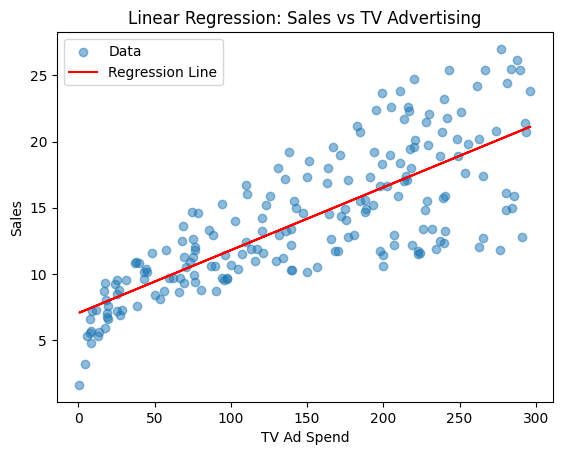

In [14]:
# Plot Regression Line (Example: TV vs Sales)
# TV only regression for visualization
X_tv = sm.add_constant(data["TV"])
print(X_tv)
model_tv = sm.OLS(Y, X_tv).fit()

y_hat = model_tv.predict(X_tv)

plt.scatter(data["TV"], Y, alpha=0.5, label="Data")
plt.plot(data["TV"], y_hat, color="red", label="Regression Line")
plt.xlabel("TV Ad Spend")
plt.ylabel("Sales")
plt.title("Linear Regression: Sales vs TV Advertising")
plt.legend()
plt.show()

     const  newspaper
0      1.0       69.2
1      1.0       45.1
2      1.0       69.3
3      1.0       58.5
4      1.0       58.4
..     ...        ...
195    1.0       13.8
196    1.0        8.1
197    1.0        6.4
198    1.0       66.2
199    1.0        8.7

[200 rows x 2 columns]


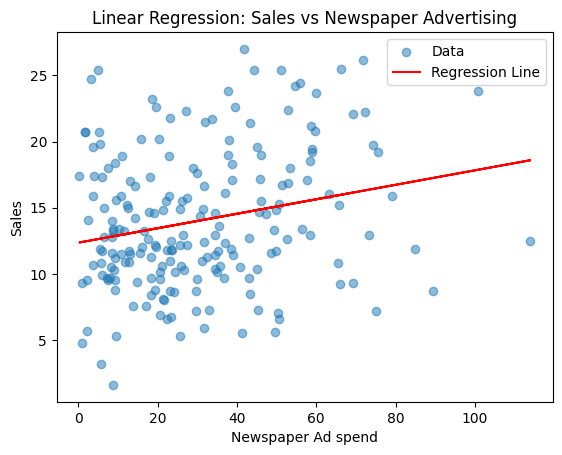

In [15]:
#Regression Line for [Newspaper vs Sales]
X_newspaper =sm.add_constant(data['newspaper'])
print(X_newspaper)
model_newspaper = sm.OLS(Y, X_newspaper).fit()

y_hat = model_newspaper.predict(X_newspaper)

plt.scatter(data["newspaper"], Y, alpha=0.5, label="Data")
plt.plot(data["newspaper"], y_hat, color="red", label="Regression Line")
plt.xlabel("Newspaper Ad spend")
plt.ylabel("Sales")
plt.title("Linear Regression: Sales vs Newspaper Advertising")
plt.legend()
plt.show()

     const  radio
0      1.0   37.8
1      1.0   39.3
2      1.0   45.9
3      1.0   41.3
4      1.0   10.8
..     ...    ...
195    1.0    3.7
196    1.0    4.9
197    1.0    9.3
198    1.0   42.0
199    1.0    8.6

[200 rows x 2 columns]


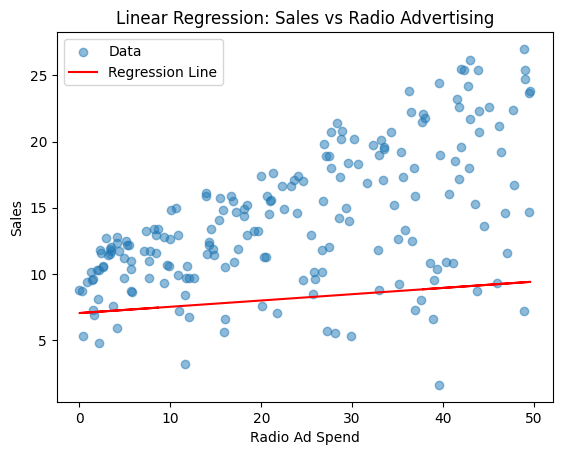

In [16]:
#Regression Line Radio vs Sales
X_radio = sm.add_constant(data["radio"])
print(X_radio)
model_radio = sm.OLS(Y, X_tv).fit()

y_hat = model_radio.predict(X_radio)

plt.scatter(data["radio"], Y, alpha=0.5, label="Data")
plt.plot(data["radio"], y_hat, color="red", label="Regression Line")
plt.xlabel("Radio Ad Spend")
plt.ylabel("Sales")
plt.title("Linear Regression: Sales vs Radio Advertising")
plt.legend()
plt.show()